## Red Mountain Spinup Analysis 
Comparison of model output to forcing.

Notes on Julian vs Gregorian dates:
The model runs on a Julian calendar, meaning that any year divisible by 4 is a leap year. In contrast, the Gregorian calendar is similar but skips certain leap years (divisible by 100 but not 400). The most relevant date is 1900 for spinup, which is a leap year in the Julian calendar but not in the Gregorian calendar. When comparing to forcing, I need to keep this in mind.

Plotting and resampling all depend on normal datetime indicies, so I am going to convert the Julian dates to Gregorian. The land_daily data is most problematic since it typically includes 1900. I will simply switch out the calendar for the output by creating a new index that starts at the same time but uses the Gregorian calendar.

In [2]:
%matplotlib ipympl
import xarray as xr
import matplotlib.pyplot as plt
import pandas as pd
import os

In [3]:
# Run configuration
snotel_site = 'Tony Grove RS'  #Use the Snotel name
spin_up = '100y'
forcings = 's00000000'
forcing_version = 'v0.4.4'  # Version of the forcing data
spinup_version = 'v1.0'
spinup_build_version = 'V0.1'
path_env = 'desktop' # 'desktop' or 'alpine'

In [4]:
# Configure environment
if path_env == 'desktop':
    output_path = 'C:/Users/clmbn/NMT_PhD/data/output' #desktop
    snotel_path = 'C:/Users/clmbn/NMT_PhD/data/snotel/' #desktop
    forcing_path = 'C:/Users/clmbn/NMT_PhD/data/forcing/' #desktop
elif path_env == 'alpine':
    output_path = r'/projects/ccox1@xsede.org/lm4px_modelling/output' #Alpine
    snotel_path = r'/projects/ccox1@xsede.org/data/snotel/'
    forcing_path = r'/projects/ccox1@xsede.org/data/forcing/'
else:
    raise ValueError("Invalid path_env. Choose 'desktop' or 'alpine'.")

In [5]:
# Convert name for output paths
site = snotel_site.replace(' ','').lower()
print(f'Output site: {site}')

Output site: tonygrovers


Load forcing:
Forcing is 10 years of NLDAS data that is then looped for the spinup period.

In [6]:
forcing_10yr = xr.open_dataset(os.path.join(forcing_path, site, f'{site}_spinup{spinup_build_version}_s00000000_{forcing_version}.nc'))

In [7]:
forcing_10yr

<xarray.Dataset> Size: 6MB
Dimensions:           (latitude: 1, longitude: 1, time: 87696)
Coordinates:
  * latitude          (latitude) float64 8B 41.89
  * longitude         (longitude) float64 8B -111.6
  * time              (time) datetime64[ns] 702kB 2000-01-01 ... 2010-01-01T2...
Data variables:
    Tair              (time, latitude, longitude) float64 702kB ...
    Qair              (time, latitude, longitude) float64 702kB ...
    Psurf             (time, latitude, longitude) float64 702kB ...
    Rainf             (time, latitude, longitude) float64 702kB ...
    Snowf             (time, latitude, longitude) float64 702kB ...
    SWdown            (time, latitude, longitude) float64 702kB ...
    LWdown            (time, latitude, longitude) float64 702kB ...
    Wind              (time, latitude, longitude) float64 702kB ...
    reference_height  (latitude, longitude) int64 8B ...
    canopy_height     (latitude, longitude) float64 8B ...

In [8]:
def get_spinup_forcing(forcing_ds: xr.Dataset, var_name: str) -> pd.Series:
    '''
    Extract a given variable (at a daily timestep) from the forcing dataset and loop it for the 100 year spinup period.
    Return a pandas Series with the looped data.
    '''
    # If 'precip' get sum of 'Rainf' and 'Snowf'
    if var_name == 'precip':
        forcing_ds = forcing_ds.assign(precip=forcing_ds['Rainf'] + forcing_ds['Snowf'])
    
    # Extract the variable data
    data = forcing_ds[var_name].isel(latitude=0, longitude=0).to_series()

    # Resample to daily frequency
    data_daily = data.resample('D').mean()

    # Loop the data for the spinup period
    # The model uses an interpolation algorithm to do the looping, but concatenating the data is sufficient for this purpose.
    # I need to leave off the last day of the data when concatenating because the spinup start and end on the same day.
    spinup_years = int(spin_up[:-1])  # Extract the number of years from the spin_up string
    looped = pd.concat([data_daily[:-1]] * int(spinup_years / 10), ignore_index=True)

    # Generate a new index that starts at the first day of the model run
    model_start_year = data_daily.index[-1].year - spinup_years
    model_start = data_daily.index[0].replace(year=model_start_year)
    looped.index = pd.date_range(start=model_start, periods=len(looped), freq='D')

    # Create date range accounting for Julian 1900 leap year if necessary
    # if model_start < pd.Timestamp('1900-03-01'):
    #     model_end = data_daily.index[-1] + pd.Timedelta(days=1)  # Add on a day to account for the leap year in 1900
    # else:
    #     model_end = data_daily.index[-1]
    # model_index = pd.date_range(start=model_start, end=model_end, freq='D')

    # Shift index by 12 hours to match model output
    looped.index = looped.index + pd.Timedelta(hours=12)

    looped.name = var_name

    return looped
    


In [9]:
# Verify the function works for Tair
test = get_spinup_forcing(forcing_10yr, 'Tair')
# test2 = forcing_10yr['Tair'].isel(latitude=0, longitude=0).to_series()
# test2.index = test2.index.to_datetimeindex()  # This will give a warning but shouldn't be problematic since the spinup forcing is > 1900
# test2 = test2.resample('D').mean()

Load diagnostics

In [10]:
output_folder = os.path.join(output_path,f'{site}/{site}_spinup_{spin_up}_{forcings}_{spinup_version}/history/')

In [11]:
# Find the land daily file name in folder and open
land_daily=None
for filename in os.listdir(output_folder):
    if filename.endswith(".land_daily.nc"):
        land_daily = xr.open_dataset(output_folder + filename)
if not land_daily:
    print('Error: no land daily found')

In [12]:
# Create a dataframe whose index is the name of the variable and the columns are: dimensions, long_name, units
daily_vars_df = pd.DataFrame({
    'dimensions': [land_daily[var].dims for var in land_daily.data_vars],
    'long_name': [land_daily[var].attrs.get('long_name', '') for var in land_daily.data_vars],
    'units': [land_daily[var].attrs.get('units', '') for var in land_daily.data_vars]
}, index=land_daily.data_vars)

In [13]:
land_daily

<xarray.Dataset> Size: 13MB
Dimensions:                  (grid_index: 1, time: 36525, nv: 2, lon: 1,
                              lonb: 2, lat: 1, latb: 2, zfull_soil: 20,
                              zhalf_soil: 21, band: 2)
Coordinates:
  * grid_index               (grid_index) float64 8B 0.0
  * time                     (time) object 292kB 1910-01-01 12:00:00 ... 2009...
  * nv                       (nv) float64 16B 1.0 2.0
  * lon                      (lon) float64 8B -111.6
  * lonb                     (lonb) float64 16B -112.1 -111.1
  * lat                      (lat) float64 8B 41.89
  * latb                     (latb) float64 16B 41.39 42.39
  * zfull_soil               (zfull_soil) float64 160B 0.01 0.04 ... 6.75 8.75
  * zhalf_soil               (zhalf_soil) float64 168B 0.0 0.02 ... 7.5 10.0
  * band                     (band) float64 16B 1.0 2.0
    geolon_t                 (grid_index) float64 8B ...
    geolat_t                 (grid_index) float64 8B ...
Data variables: (12/56)
    fco2                     (time, grid_index) float32 146kB ...
    t_ref                    (time, grid_index) float32 146kB ...
    co2_mol_flux             (time, grid_index) float32 146kB ...
    co2_mol_flux1            (time, grid_index) float32 146kB ...
    btot                     (time, grid_index) float32 146kB ...
    Ctot                     (time, grid_index) float32 146kB ...
    ...                       ...
    drydep_md                (time, grid_index) float32 146kB ...
    drydep_om                (time, grid_index) float32 146kB ...
    average_T1               (time) datetime64[ns] 292kB ...
    average_T2               (time) datetime64[ns] 292kB ...
    average_DT               (time) timedelta64[ns] 292kB ...
    time_bnds                (time, nv) object 584kB ...
Attributes:
    filename:          land_daily.nc
    title:             
    associated_files:  soil_area: land_static.nc land_area: land_static.nc
    grid_type:         regular
    grid_tile:         N/A

#### Calendar conversion:
Create a new calendar index that is gregorian starting at the same time as the output.

In [14]:
# Get the first time coordinate from the daily dataset
model_start_str = land_daily['time'].to_index()[0].strftime('%Y-%m-%d 12:00')
model_end_str = land_daily['time'].to_index()[-1].strftime('%Y-%m-%d 12:00')
model_start = pd.Timestamp(model_start_str)

# Create a date range for the model index
# Adjust the end date to account for the leap year in 1900
if model_start < pd.Timestamp('1900-03-01'):
    model_end = pd.Timestamp(model_end_str) + pd.Timedelta(days=1)  # Add on a day to account for the leap year in 1900
else:
    model_end = pd.Timestamp(model_end_str) 

output_index_gregorian = pd.date_range(start=model_start, end=model_end, freq='D')

### Analysis: Snow and temperature
For daily analysis, I want to see if the snow and ground temperature are reasonable. Relevant land daily variables are: t_ref, Tgrnd, snow_depth, snow_frac.

t_ref is described as 2m air temperature, which should be close but maybe not exactly the same as Tair forcing. Tgrnd is ground temperature, but I wonder if it is actually surface temperature and not representative of the ground under the snow.

In [15]:
model_surface_data = land_daily[['t_ref', 'snow_frac', 'snow_depth', 'Tgrnd']].isel(grid_index=0).to_dataframe()
model_surface_data.index = output_index_gregorian
model_surface_data = model_surface_data[['t_ref', 'snow_frac', 'snow_depth', 'Tgrnd']]  #Just get the variables of interest

In [16]:
# Change temperature units to Celsius
model_surface_data['t_ref'] = model_surface_data['t_ref'] - 273.15  # Convert from Kelvin to Celsius
model_surface_data['Tgrnd'] = model_surface_data['Tgrnd'] - 273.15  # Convert from Kelvin to Celsius

In [17]:
# Get the forcing Tair
Tair = get_spinup_forcing(forcing_10yr, 'Tair')
Tair = Tair - 273.15  # Convert from Kelvin to Celsius

<Axes: >

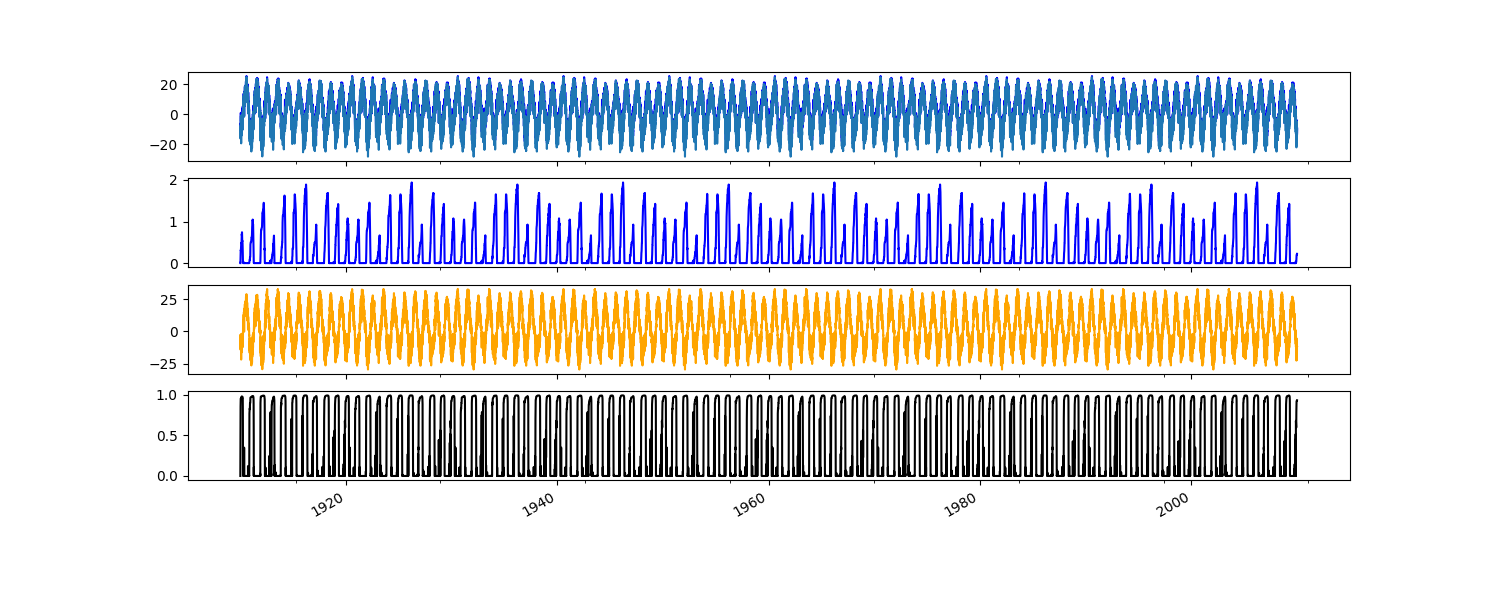

In [18]:
fig, ax = plt.subplots(4,1,sharex=True,figsize=(15, 6))
Tair.plot(ax=ax[0], label='Tair forcing', color='blue')
model_surface_data['t_ref'].plot(ax=ax[0], label='t_ref')
model_surface_data['snow_depth'].plot(ax=ax[1], label='snow', color='blue')
model_surface_data['Tgrnd'].plot(ax=ax[2], label='Tgrnd', color='orange')
model_surface_data['snow_frac'].plot(ax=ax[3], label='snow_frac', color='black')


Ground temperature shouldn't be getting cold in the winter underneath the snow. 

In [19]:
# Extract soil temperatures
def extract_soil_data(soil_var) -> pd.DataFrame:
    soil_data = land_daily[[soil_var]].isel(grid_index=0).to_dataframe()
    soil_data_df = soil_data.reset_index().pivot(index='time', columns='zfull_soil', values=soil_var)
    soil_data_df.columns.name = 'Depth'
    soil_data_df.index = output_index_gregorian
    soil_data_df.columns = [f"{col:03.2f}" for col in soil_data_df.columns]
    return soil_data_df

soil_T = extract_soil_data('soil_T')

In [20]:
# Convert soil temperature to Celsius
soil_T = soil_T - 273.15  # Convert from Kelvin to Celsius

Text(0, 0.5, 'Snow Fraction')

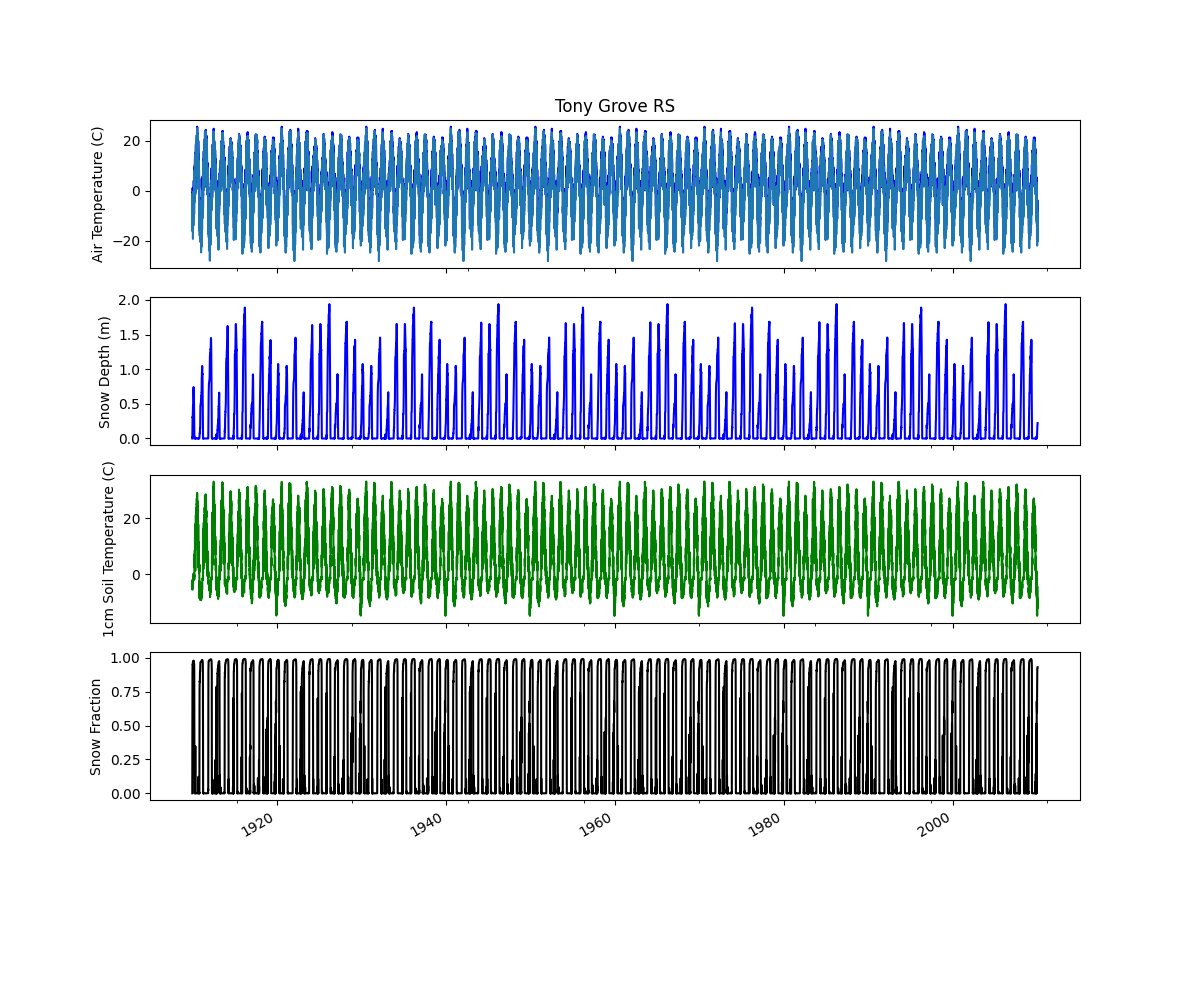

In [21]:
fig, ax = plt.subplots(4,1,sharex=True,figsize=(12, 10))
Tair.plot(ax=ax[0], label='Tair forcing', color='blue')
model_surface_data['t_ref'].plot(ax=ax[0], label='t_ref')
model_surface_data['snow_depth'].plot(ax=ax[1], label='snow', color='blue')
soil_T['0.01'].plot(ax=ax[2], label='Soil T at 0.01m', color='green')  # Plot soil temperature at 0.01m depth
model_surface_data['snow_frac'].plot(ax=ax[3], label='snow_frac', color='black')
ax[0].set_title(f'{snotel_site}')
ax[0].set_ylabel('Air Temperature (C)')
ax[1].set_ylabel('Snow Depth (m)')
ax[2].set_ylabel('1cm Soil Temperature (C)')
ax[3].set_ylabel('Snow Fraction')

Soil T at 0.01m does show some insulation from air temperature, but my intuition is that it should basically be zero.

### Soil temperature profile

array([<Axes: >, <Axes: >, <Axes: >, <Axes: >], dtype=object)

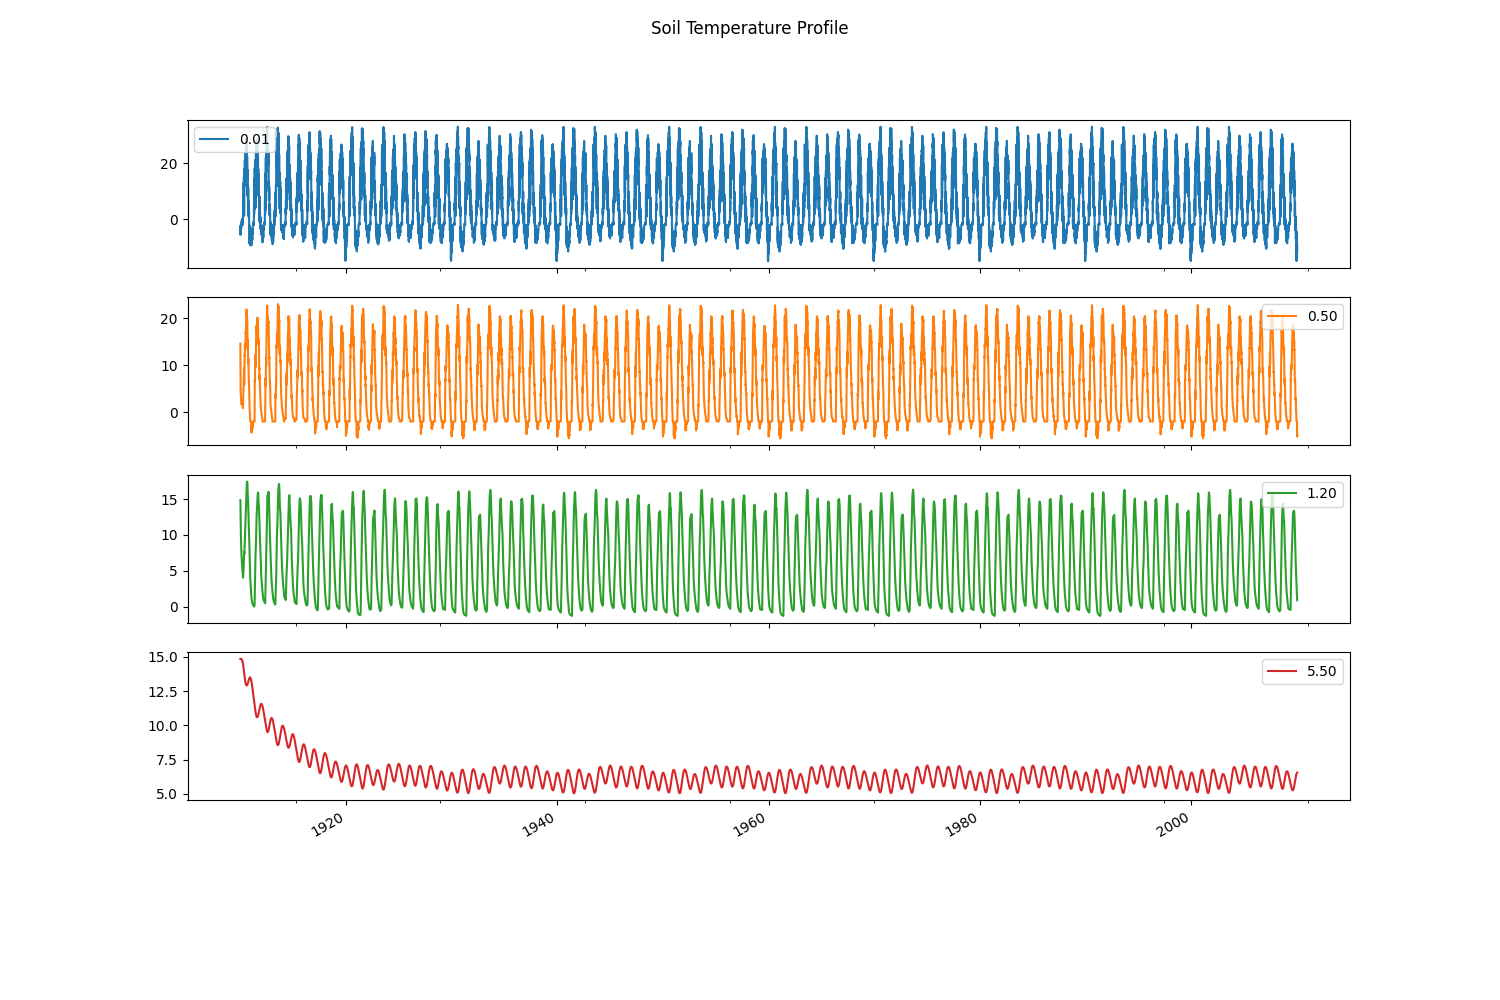

In [22]:
# Plot soil temperatures at 0.01, 0.50, 1.20, 5.50m
soil_T[['0.01', '0.50', '1.20', '5.50']].plot(subplots=True, figsize=(15, 10), title='Soil Temperature Profile')

#### Soil liquid/ice water content
These variables are currently in monthly data.

In [23]:
# Find the land month file name in folder and open
land_month=None
for filename in os.listdir(output_folder):
    if filename.endswith(".land_month.nc"):
        land_month = xr.open_dataset(output_folder + filename)
if not land_month:
    print('Error: no land daily found')

In [24]:
# Create a dataframe whose index is the name of the variable and the columns are: dimensions, long_name, units
land_vars_df = pd.DataFrame({
    'dimensions': [land_month[var].dims for var in land_month.data_vars],
    'long_name': [land_month[var].attrs.get('long_name', '') for var in land_month.data_vars],
    'units': [land_month[var].attrs.get('units', '') for var in land_month.data_vars]
}, index=land_month.data_vars)

In [25]:
# Function for extracting soil data
def extract_soil_data_month(soil_var) -> pd.DataFrame:
    soil_data = land_month[[soil_var]].isel(grid_index=0).to_dataframe()
    soil_data_df = soil_data.reset_index().pivot(index='time', columns='zfull_soil', values=soil_var)
    soil_data_df.columns.name = 'Depth'
    soil_data_df.index = xr.CFTimeIndex(soil_data_df.index).to_datetimeindex() # This shouldn't matter since the data is monthly
    soil_data_df.columns = [f"{col:03.2f}" for col in soil_data_df.columns]
    return soil_data_df

In [26]:
soil_liq = extract_soil_data_month('soil_liq')
soil_ice = extract_soil_data_month('soil_ice')

C:\Users\clmbn\AppData\Local\Temp\ipykernel_20844\2282353683.py:6: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, 'julian', to a pandas.DatetimeIndex, which uses dates from the standard calendar.  This may lead to subtle errors in operations that depend on the length of time between dates.
  soil_data_df.index = xr.CFTimeIndex(soil_data_df.index).to_datetimeindex() # This shouldn't matter since the data is monthly
C:\Users\clmbn\AppData\Local\Temp\ipykernel_20844\2282353683.py:6: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, 'julian', to a pandas.DatetimeIndex, which uses dates from the standard calendar.  This may lead to subtle errors in operations that depend on the length of time between dates.
  soil_data_df.index = xr.CFTimeIndex(soil_data_df.index).to_datetimeindex() # This shouldn't matter since the data is monthly


In [27]:
Tair_month = Tair.resample('MS').mean()

# Shift index forward 15 days to match the land month data
Tair_month.index = Tair_month.index + pd.DateOffset(days=15)

array([<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >], dtype=object)

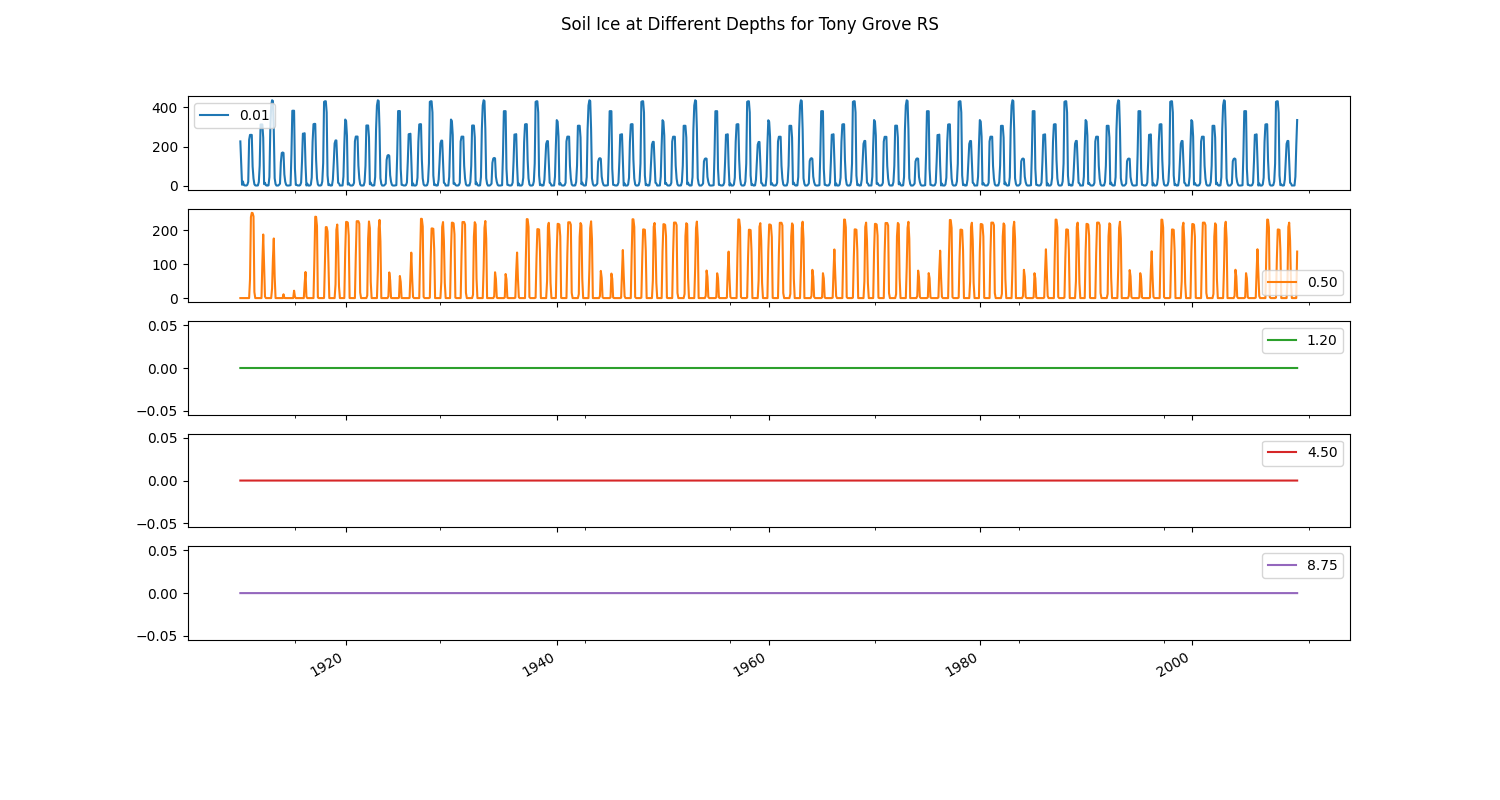

In [28]:
soil_ice[['0.01','0.50','1.20','4.50','8.75']].plot(subplots=True, figsize=(15, 8), title='Soil Ice at Different Depths for ' + snotel_site)

array([<Axes: >, <Axes: >, <Axes: >, <Axes: >, <Axes: >], dtype=object)

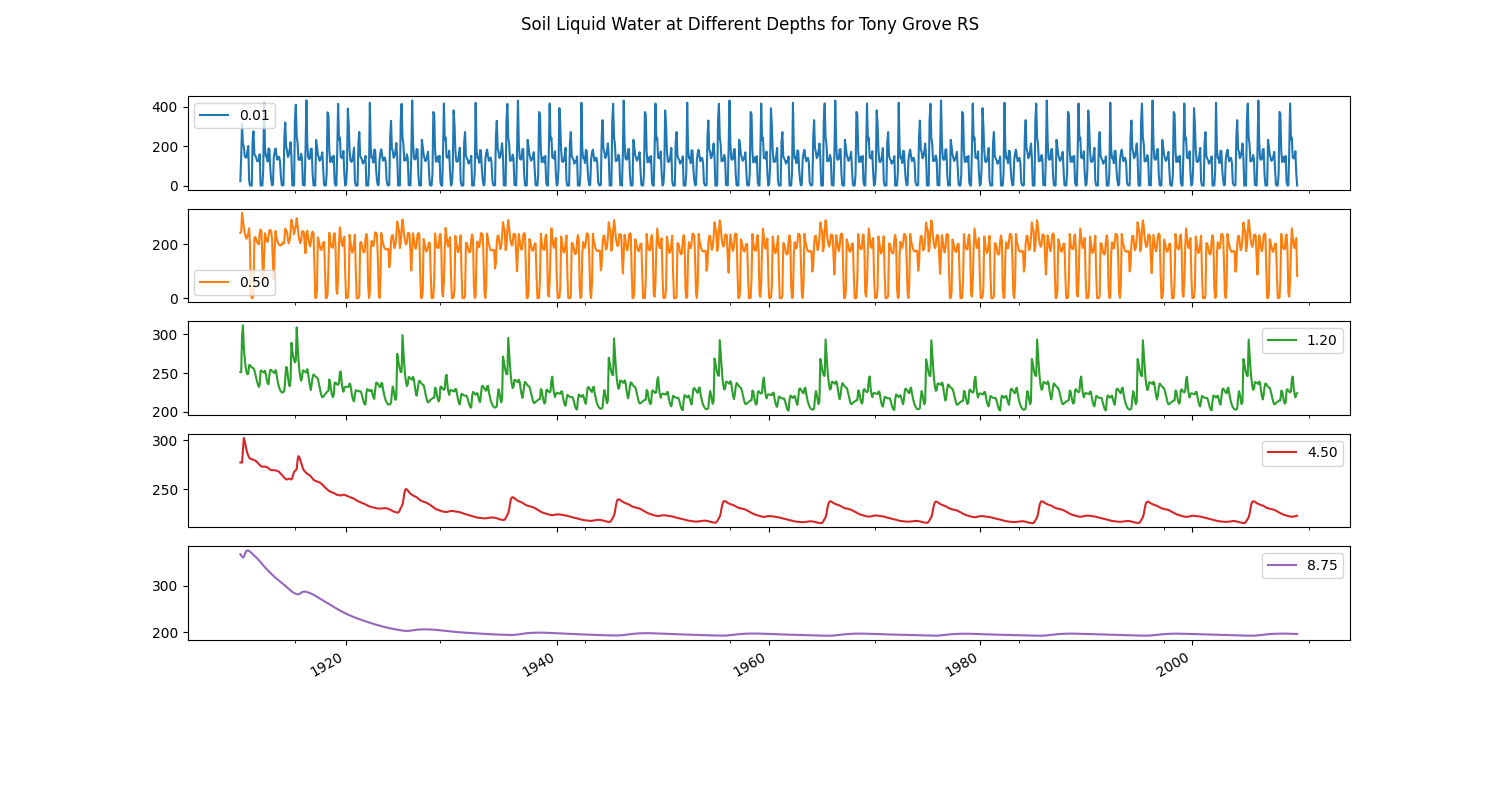

In [29]:
soil_liq[['0.01','0.50','1.20','4.50','8.75']].plot(subplots=True, figsize=(15, 8), title='Soil Liquid Water at Different Depths for ' + snotel_site)